# Introduction
This is the assignment submission for the course DSC212 - Mathematical Foundation to Data Science for the year 2026 at IISER TVM.

This notebooks implements recursive bipartion clustering with modularity to identify the different communities in the graph after a split.
The nodes are people and the edges are the connection between each person. This assignment is based on predicting how the split will happen given a conflict occurs.

# Initialising and Set-Up
I first start by importing the basic required libraries that will be used throughout this notebook and visualising the karate club graph.

Note that this graph that I used was already available in `networkx`.

The function `np.set_printoptions()` is used to make the array output look clean and readable by approximating each values to set decimal places.

`numpy` is used for performing matrix operations.

`matplotlib.pyplot` is used for visualisation.

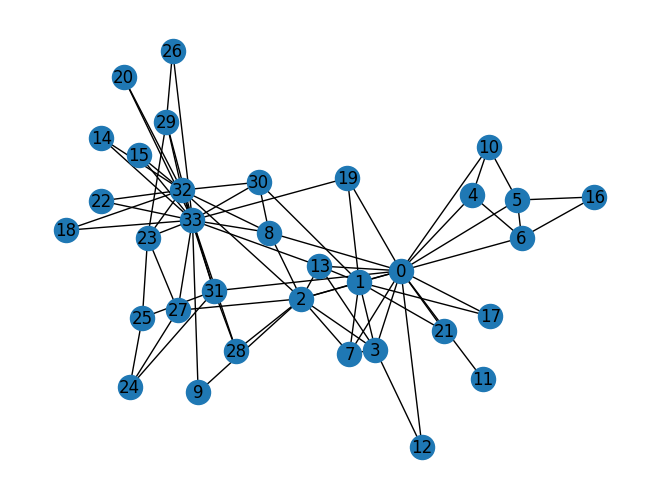

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
np.set_printoptions(precision=2, suppress=True)
g=nx.karate_club_graph()
nx.draw(g, with_labels=True)
plt.show()

# Getting the Modularity Matrix
**Modularity** is a metric used to measure the strength of dividing a graph into communities or clusters. It provides a measure of how well the graph is partitioned into groups.

For the given graph, in order to separate the nodes I need some measure to detect which group they belong to. Instead of evaluating it through the raw data given (adjacency matrix), the modularity matrix gives me a probability of how strong the connection is.

The modularity matrix, $B$ is defined as
$$B=A-\frac{kk^T}{2m}$$
where
$A$ is the Adjacency Matrix, $m$ is the Number of Egdes, and $k$ is the Node Degree Vector.

Note that $A$ should be taken unweighted. Weighted $A$ will give us only 2 communities which is the initial split.

In [ ]:
m=g.number_of_edges()
A=nx.adjacency_matrix(g, weight=None).toarray()
deg=np.array([d for _, d in g.degree()])
expected=np.outer(deg, deg)/(2*m)
B_global=A-expected
print(B_global)

[[-1.64  0.08 -0.03 ...  0.38 -1.23 -1.74]
 [ 0.08 -0.52  0.42 ... -0.35 -0.69 -0.98]
 [-0.03  0.42 -0.64 ... -0.38  0.23 -1.09]
 ...
 [ 0.38 -0.35 -0.38 ... -0.23  0.54  0.35]
 [-1.23 -0.69  0.23 ...  0.54 -0.92 -0.31]
 [-1.74 -0.98 -1.09 ...  0.35 -0.31 -1.85]]


# First Bipartition
To get the first two communities I got the leading eigenvalue and eigenvectors of $B$ and assigned them labels $$s = \begin{cases}1 & u_i>0\\ -1 & \text{else} \end{cases}$$
where $u_i$ represents the leading eigenvector.

This represents the first two communities of the graph.

In [ ]:
eigenvalues, eigenvectors= np.linalg.eig(B_global)
leading_index= np.argmax(eigenvalues)
leading_eigenvector= eigenvectors[:, leading_index].real
leading_eigenvalue= eigenvalues[leading_index].real
print("Leading Eigenvalue: ", leading_eigenvalue)
print("Leading eigenvectors: \n", leading_eigenvector)
label_vec=leading_eigenvector.copy()
i=0
while i<g.number_of_nodes():
  if leading_eigenvector[i]>0:
    label_vec[i]=1
  else:
    label_vec[i]=-1
  i+=1
print("Assigned label vectors: \n", label_vec)


Leading Eigenvalue:  4.977080225729895
Leading eigenvectors: 
 [ 0.39  0.27  0.13  0.25  0.13  0.15  0.15  0.21 -0.05 -0.05  0.13  0.08
  0.13  0.14 -0.14 -0.14  0.06  0.13 -0.14  0.06 -0.14  0.13 -0.14 -0.22
 -0.06 -0.08 -0.12 -0.1  -0.07 -0.21 -0.1  -0.1  -0.32 -0.37]
Assigned label vectors: 
 [ 1.  1.  1.  1.  1.  1.  1.  1. -1. -1.  1.  1.  1.  1. -1. -1.  1.  1.
 -1.  1. -1.  1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]


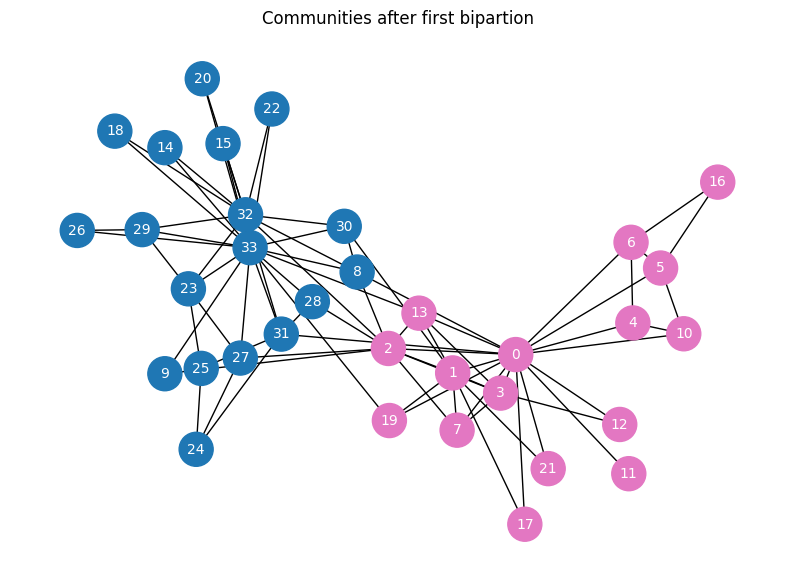

In [ ]:
pos = nx.spring_layout(g, seed=30)

colors = ['tab:pink' if l == 1 else 'tab:blue' for l in label_vec]

plt.figure(figsize=(10, 7))
nx.draw_networkx(g, pos, node_color = colors, with_labels = True,
                 node_size = 600, font_size = 10, font_color = 'white',
                 edge_color = 'black')
plt.title("Communities after first bipartion")
plt.axis('off')
plt.show()

# Getting the Rest of the Communities
The first bipartition is the actual split that happened. The 4 communities that I got is a prediction on how these two communities could split further.

To do this I used `stack` method.

`stack` is a LIFO (Last In First Out) here initialises the nodes in the karate club graph, storing the sub communities that can be slit further.

`final_communities` store the communities that cannot be split further.

`stack.pop()` removes the top community from `stack` and adds it to another list `community`. I run a loop so that a single node doesnt partition further and gets added to the list `final_community`.

`B_global[np.ix_(idx, idx)]` makes sure that the modularity matrix corresponds to the selected community.

Then I find the leading eigenvectors and eigenvalues for each `B_sub` and assign them labels: +1 or -1, depending upon their signs, like I did for the first bipartition.

`s=np.where(eigenvectors[:, leading_idx]>=0, 1, -1)` does the work of assigning the labels by pointing to the indices of the eigenvectors corresponding to the leading eigenvalue.

I calculate $\Delta Q$ for each sub community and check for 2 cases.
1. $\Delta Q > 0$: separate each node of the sub community into 2 communities by the signs of their labels
2. $\Delta Q \leq 0$: the split provides no modularity and its an optimal split.

For case 1, if the two communities are non-epmty, I add them back to `stack` to split them further. In the end I printed the final sorted list to get 5 communities.

NOTE: Ideally, node 11 should not be separated as an individual community, that happened here. To rectify that, Newman made a correction that I commented in the code below. Using that I got 4 communities, without that I got 5 communities.

In [ ]:
stack=[list(g.nodes())]
final_communities=[]
while len(stack)>0:
    community=stack.pop()
    if len(community)<=1:
        final_communities.append(community)
        continue
    idx=np.array(community)
    B_sub=B_global[np.ix_(idx, idx)]
    #np.fill_diagonal(B_sub, B_sub.diagonal()-np.sum(B_sub, axis=1))
    eigenvalues, eigenvectors=np.linalg.eigh(B_sub)
    leading_idx=np.argmax(eigenvalues)
    s=np.where(eigenvectors[:, leading_idx]>=0, 1, -1)
    delta_Q = (1 / (4 * m)) * (s.T @ B_sub @ s)
    if delta_Q>0:
        comm_1=[community[i] for i in range(len(community)) if s[i]==1]
        comm_2=[community[i] for i in range(len(community)) if s[i]==-1]
        if len(comm_1)>0 and len(comm_2)>0:
            stack.append(comm_1)
            stack.append(comm_2)
        else:
            final_communities.append(community)
    else:
        final_communities.append(community)
final_communities=sorted(final_communities, key=lambda c:min(c))
print(f"Total Communities Found: {len(final_communities)}\n")
for i, comm in enumerate(final_communities, 1):
    print(f"Community {i} ({len(comm)} nodes):{sorted(comm)}")

Total Communities Found: 5

Community 1 (10 nodes):[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2 (5 nodes):[4, 5, 6, 10, 16]
Community 3 (13 nodes):[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Community 4 (1 nodes):[11]
Community 5 (5 nodes):[24, 25, 27, 28, 31]


# Visualisation of the Communities After Each Iteration

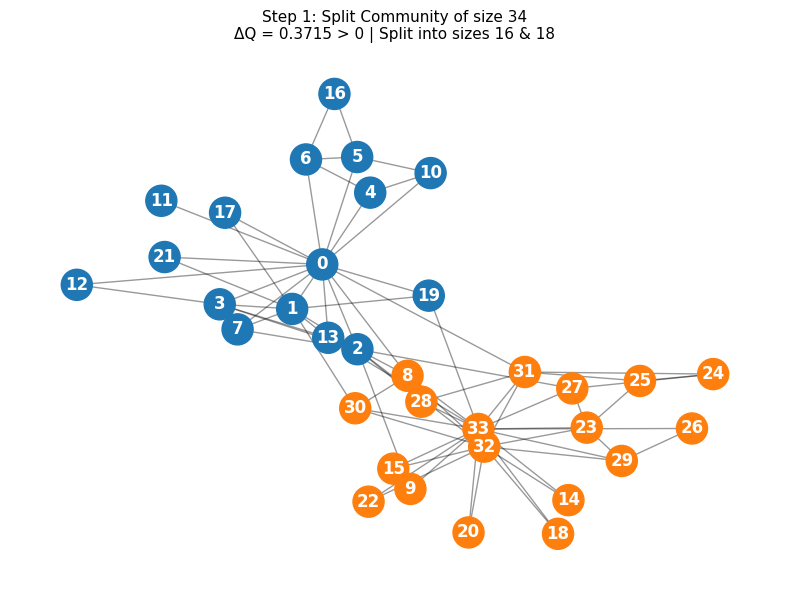

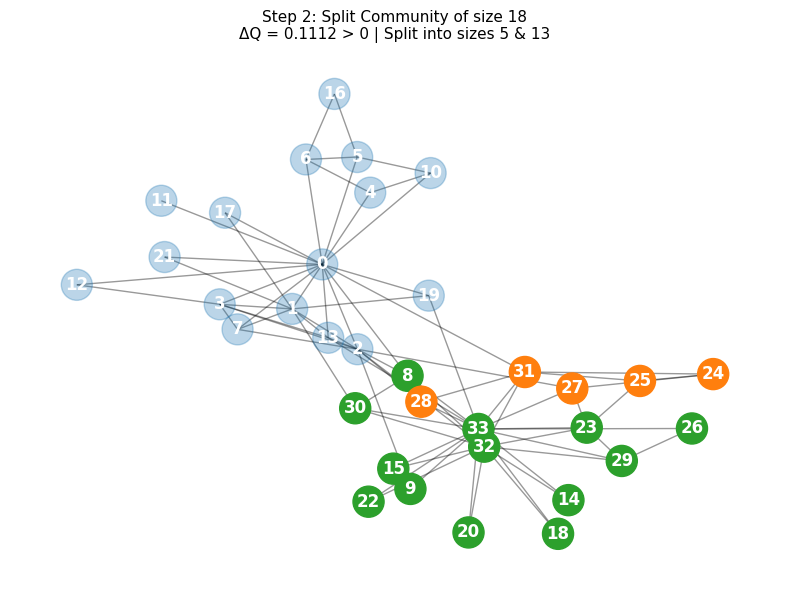

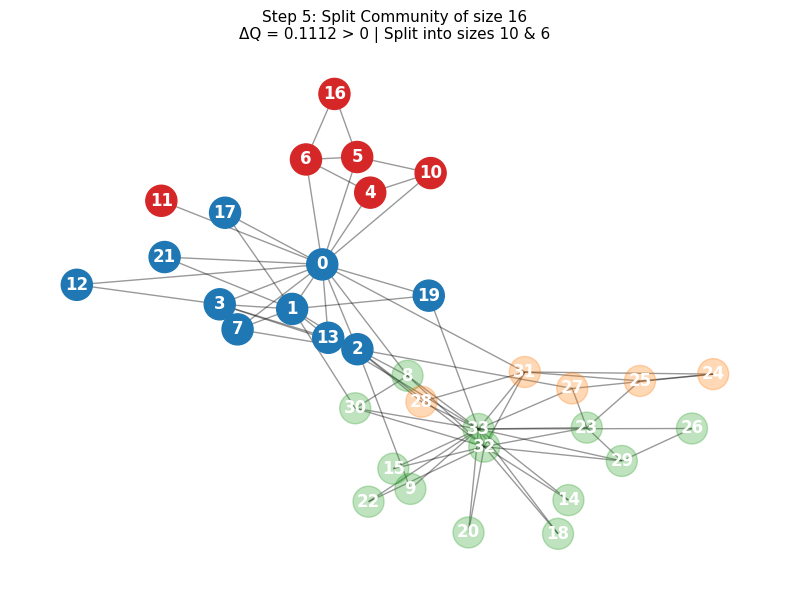

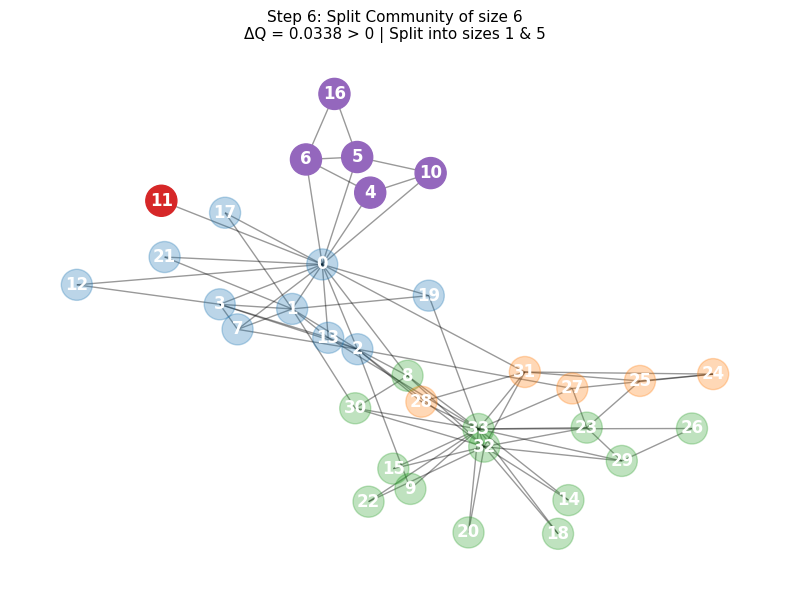

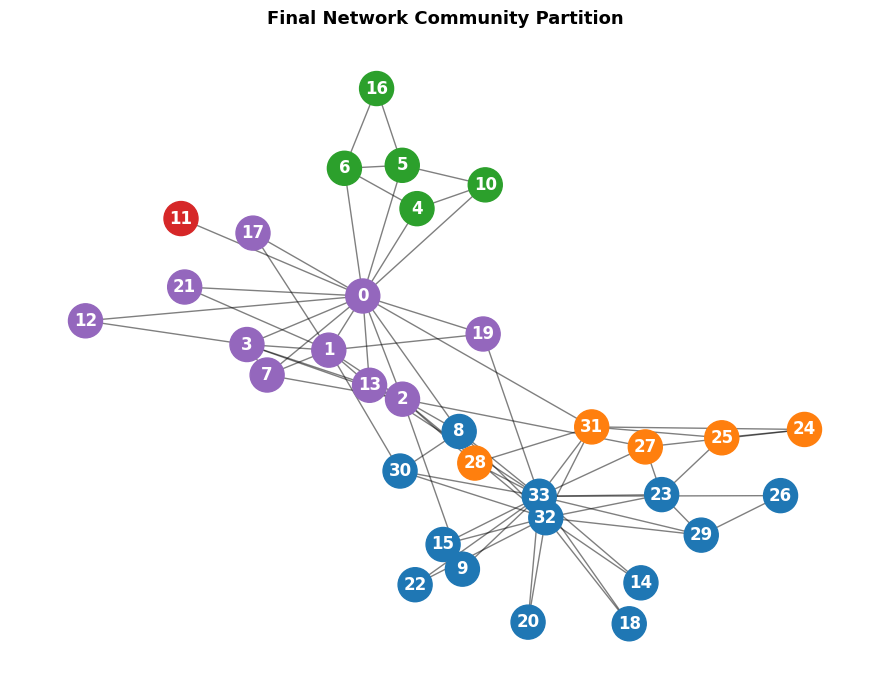

In [ ]:
# Color palette for distinct final/active communities
palette = plt.cm.tab10.colors

# Stack tracks (community_node_list, parent_color_index)
stack = [(list(g.nodes()), 0)]
final_communities = []
step_count = 0

# Track community assignments for plotting at each stage
# Maps node -> assigned community ID (used for coloring)
node_community_map = {n: 0 for n in g.nodes()}
color_counter = 0

while len(stack) > 0:
    community, current_color_idx = stack.pop()

    if len(community) <= 1:
        final_communities.append(community)
        continue

    idx = np.array(community)
    B_sub = B_global[np.ix_(idx, idx)]

    # Optional Modularity Adjustment for Sub-graphs (Newman's spectral modularity enhancement)
    # np.fill_diagonal(B_sub, B_sub.diagonal() - np.sum(B_sub, axis=1))

    eigenvalues, eigenvectors = np.linalg.eigh(B_sub)
    leading_idx = np.argmax(eigenvalues)
    s = np.where(eigenvectors[:, leading_idx] >= 0, 1, -1)
    delta_Q = (1 / (4 * m)) * (s.T @ B_sub @ s)

    step_count += 1

    if delta_Q > 0:
        comm_1 = [community[i] for i in range(len(community)) if s[i] == 1]
        comm_2 = [community[i] for i in range(len(community)) if s[i] == -1]

        if len(comm_1) > 0 and len(comm_2) > 0:
            color_1 = current_color_idx
            color_counter += 1
            color_2 = color_counter

            # Update temporary map for step visualization
            for n in comm_1:
                node_community_map[n] = color_1
            for n in comm_2:
                node_community_map[n] = color_2

            stack.append((comm_1, color_1))
            stack.append((comm_2, color_2))

            # --- Visualization per successful split ---
            plt.figure(figsize=(8, 6))
            node_colors = [palette[node_community_map[n] % len(palette)] for n in g.nodes()]

            # Highlight non-target nodes with lower opacity
            node_alphas = [1.0 if n in community else 0.3 for n in g.nodes()]

            nx.draw_networkx_nodes(
                g, pos,
                node_color=node_colors,
                node_size=500,
                alpha=node_alphas
            )
            nx.draw_networkx_edges(g, pos, alpha=0.4)
            nx.draw_networkx_labels(g, pos, font_color="white", font_weight="bold")

            plt.title(
                f"Step {step_count}: Split Community of size {len(community)}\n"
                f"ΔQ = {delta_Q:.4f} > 0 | Split into sizes {len(comm_1)} & {len(comm_2)}",
                fontsize=11
            )
            plt.axis("off")
            plt.tight_layout()
            plt.show()
        else:
            final_communities.append(community)
    else:
        # Plot attempted split that was rejected due to delta_Q <= 0
        plt.figure(figsize=(8, 6))
        node_colors = [palette[node_community_map[n] % len(palette)] for n in g.nodes()]

        nx.draw_networkx_nodes(g, pos, node_color=node_colors, node_size=500)
        nx.draw_networkx_edges(g, pos, alpha=0.4)
        nx.draw_networkx_labels(g, pos, font_color="white", font_weight="bold")

        plt.title(
            f"Step {step_count}: Evaluated Community {sorted(community)}\n"
            f"ΔQ = {delta_Q:.4f} <= 0 (No further split)",
            fontsize=11
        )
        plt.axis("off")
        plt.tight_layout()
        plt.show()

        final_communities.append(community)


# Final Community Map Plot
plt.figure(figsize=(9, 7))
final_node_color_map = {}
for idx, comm in enumerate(final_communities):
    for node in comm:
        final_node_color_map[node] = idx

colors = [palette[final_node_color_map[n] % len(palette)] for n in g.nodes()]
nx.draw_networkx_nodes(g, pos, node_color=colors, node_size=600)
nx.draw_networkx_edges(g, pos, alpha=0.5)
nx.draw_networkx_labels(g, pos, font_color="white", font_weight="bold")
plt.title("Final Network Community Partition", fontsize=13, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

# Evolution of Each Metric Across Iterations for Every Node

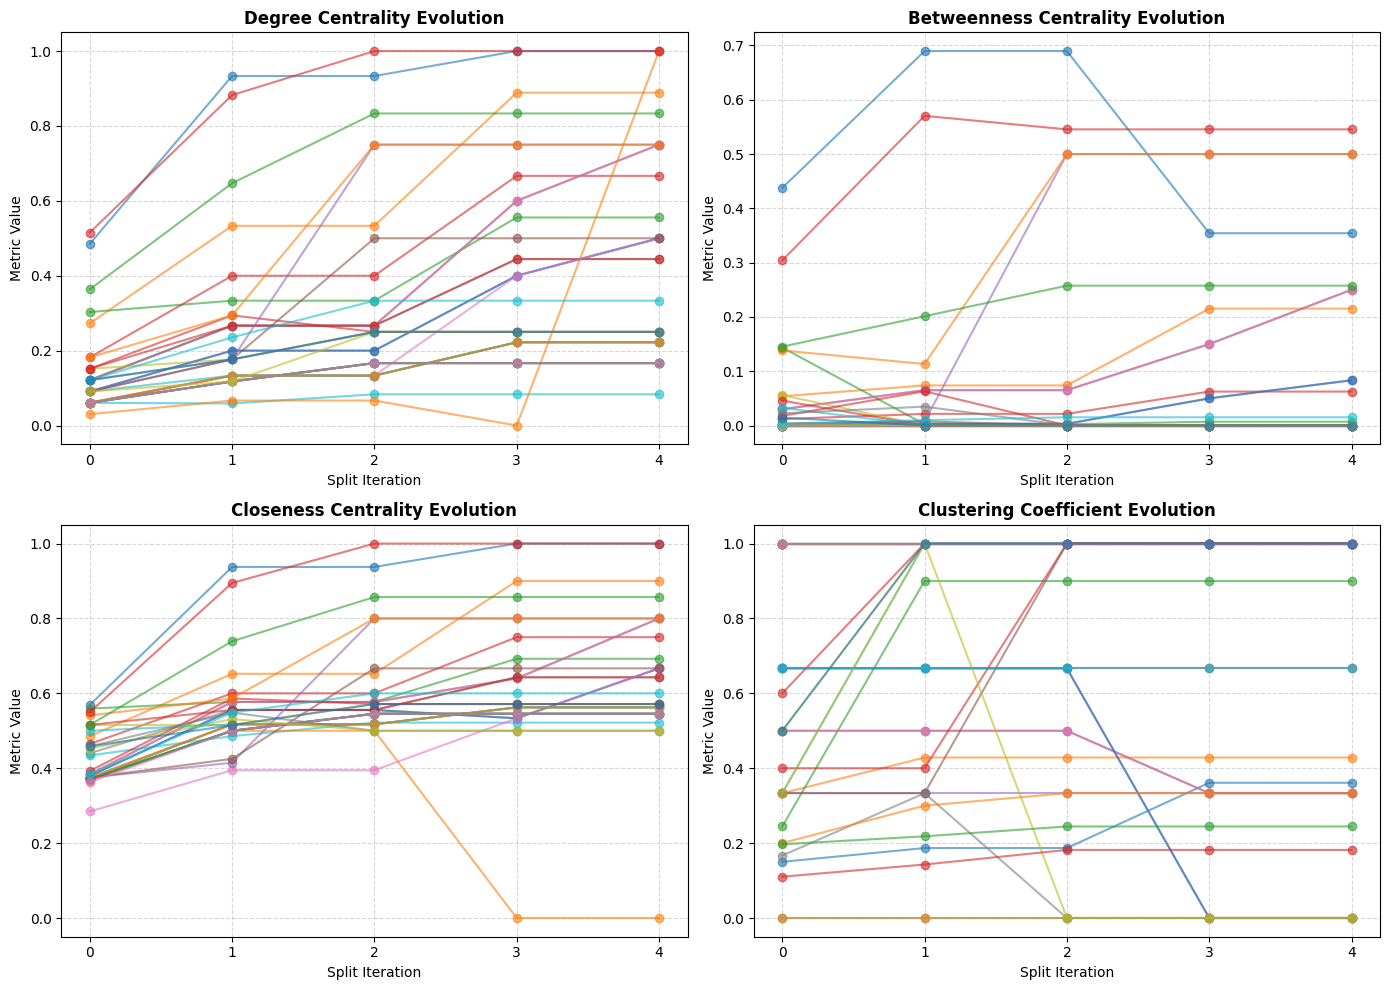

In [ ]:
# Data structure to track evolution of node metrics across split iterations
history = {
    'degree_centrality': [],
    'betweenness_centrality': [],
    'closeness_centrality': [],
    'clustering': []
}

def record_subgraph_metrics(current_partition, g):
    """
    Computes centrality and clustering metrics on the induced subgraphs
    formed by the current community partition.
    """
    deg_cent, bet_cent, clo_cent, clust = {}, {}, {}, {}

    for comm in current_partition:
        subg = g.subgraph(comm)

        # Calculate NetworkX metrics for the subgraph
        dc = nx.degree_centrality(subg)
        bc = nx.betweenness_centrality(subg)
        cc = nx.closeness_centrality(subg)
        cl = nx.clustering(subg)

        deg_cent.update(dc)
        bet_cent.update(bc)
        clo_cent.update(cc)
        clust.update(cl)

    history['degree_centrality'].append(deg_cent)
    history['betweenness_centrality'].append(bet_cent)
    history['closeness_centrality'].append(clo_cent)
    history['clustering'].append(clust)

# Record initial state (Iteration 0 - entire graph as 1 community)
stack = [list(g.nodes())]
final_communities = []
active_partition = [list(g.nodes())]
record_subgraph_metrics(active_partition, g)

# --- Hierarchical Splitting Loop ---
while len(stack) > 0:
    community = stack.pop()

    if len(community) <= 1:
        final_communities.append(community)
        continue

    idx = np.array(community)
    B_sub = B_global[np.ix_(idx, idx)]

    eigenvalues, eigenvectors = np.linalg.eigh(B_sub)
    leading_idx = np.argmax(eigenvalues)
    s = np.where(eigenvectors[:, leading_idx] >= 0, 1, -1)
    delta_Q = (1 / (4 * m)) * (s.T @ B_sub @ s)

    if delta_Q > 0:
        comm_1 = [community[i] for i in range(len(community)) if s[i] == 1]
        comm_2 = [community[i] for i in range(len(community)) if s[i] == -1]

        if len(comm_1) > 0 and len(comm_2) > 0:
            stack.append(comm_1)
            stack.append(comm_2)

            # Update active partition list
            active_partition.remove(community)
            active_partition.append(comm_1)
            active_partition.append(comm_2)

            # Record subgraph metrics at this split iteration
            record_subgraph_metrics(active_partition, g)
        else:
            final_communities.append(community)
    else:
        final_communities.append(community)

# --- Plot Metric Evolution Across Iterations for Every Node ---
metrics = ['degree_centrality', 'betweenness_centrality', 'closeness_centrality', 'clustering']
titles = ['Degree Centrality Evolution', 'Betweenness Centrality Evolution',
          'Closeness Centrality Evolution', 'Clustering Coefficient Evolution']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
num_iterations = len(history['degree_centrality'])
iterations = list(range(num_iterations))

for ax, metric, title in zip(axes.flatten(), metrics, titles):
    for node in g.nodes():
        node_metric_values = [history[metric][it][node] for it in range(num_iterations)]
        ax.plot(iterations, node_metric_values, marker='o', alpha=0.6, label=f'Node {node}' if node < 5 else "")

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Split Iteration')
    ax.set_ylabel('Metric Value')
    ax.set_xticks(iterations)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Discussion
**Key Central Nodes Across The Split**

*   Node 0 and Node 33 constistently retain high degree centrality and closeness centrality across all iteration.
*   Bridge nodes (e.g. 2, 8, 13) experience a steep drop of betweenness centrality after the first split.

**How Community Structure Affects the Metrics?**

*   Degree Centrality($C_D$): $$C_D=\frac{k_i}{n-1}$$
$k_i$ remains the same but $n$ decreases as more splits happen. So as number of communities increase, the normalised degree centrality increases.

*   Betweenness Centrality($C_B$): $$C_B=\sum_{s \neq i \neq t} \frac{σ_{st}(i)}{σ_{st}}$$
Betweenness centrality decreases for bridge nodes as split happens.

*   Closeness Centrality($C_C$): $$C_C=\frac{n-1}{∑_{i \neq j}d(i,j)}$$
In the global graph the distance nodes across opposiite clusters increases the average path length. After splitting, the clustering decreases the path length and hence the closeness centrality increases.

*  Clustering Coefficient($C$): $$C=\frac{2T(i)}{k_i(k_i-1)}$$
It increases because splitting remove cross community egdes.




# Reference
Newman (2006), "Modularity and community structure in networks". PNAS 103(23):8577-8582.

### Usage of A.I.
I wrote most of the code myself. A.I. was used in minor debugging the main peice of code that was written for bipartitioning and the Newman correction (did not separate out node 11 as a separate community). A.I. was mostly used for visualising purposes that I struggled with.